# 06 — Thresholding, morphology, and clean segmentation masks

**Level:** Beginner → intermediate · 90–120 minutes  
**Prerequisites:** Read lessons 01–05: grayscale, masks, histograms, and filtering

## What you will build and learn

- Choose global, Otsu, or adaptive thresholds
- Explain erosion, dilation, opening, and closing
- Measure segmentation quality against known labels
- Recover a document mask under uneven illumination

## How to use this lesson

Run cells in order with **Shift+Enter**. Predict the result before running each example, then change one parameter and explain what changed. Every default example works offline after setup. Each notebook creates its own data, so previous notebooks do not need to have been run.

Try the exercises before reading the worked solutions. Use **Kernel → Restart Kernel and Run All Cells** to check that your work is reproducible. Keep your own changes in a duplicate notebook if you want to retain the reference version.


## Setup

The cell below imports the libraries and the small display/file helpers. Algorithms are written in the lesson cells. Color arrays passed to `show_images` are assumed to be BGR (OpenCV's usual order); the helper converts them to RGB for Matplotlib. Grayscale arrays are displayed directly. `rng` is a repeatable random generator, so running the notebook again reproduces its sample data.


In [1]:
from pathlib import Path
import sys

# Locate the project whether Jupyter starts in the project or notebooks folder.
start = Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents) if (p / "course_utils.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the OpenCV Practical project.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt
from course_utils import show_images, make_scene, load_image, save_image

rng = np.random.default_rng(42)
cv2.setRNGSeed(42)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
print(f"OpenCV {cv2.__version__} | NumPy {np.__version__}")


OpenCV 4.14.0 | NumPy 2.5.3


## Step 1 — Turn intensity into a yes/no decision

Thresholding assigns pixels to groups using their values. With `THRESH_BINARY`, values
strictly greater than the threshold become `maxval`; the rest become zero. With
`THRESH_BINARY_INV`, the assignment is reversed. Keep a clear convention: in this
lesson **white means foreground**, whether the original object was dark or bright.

`cv2.threshold` returns two values: the threshold actually used and the output image.
The underscore `_` is a conventional name for a result we do not need.


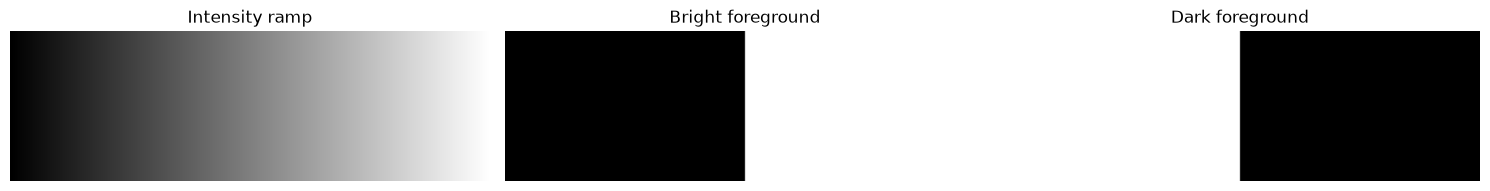

Threshold used: 127.0


In [2]:
ramp = np.tile(np.arange(256, dtype=np.uint8), (80, 1))
threshold_value = 127
used_threshold, binary = cv2.threshold(ramp, threshold_value, 255, cv2.THRESH_BINARY)
_, inverse_binary = cv2.threshold(ramp, threshold_value, 255, cv2.THRESH_BINARY_INV)
show_images([ramp, binary, inverse_binary], ["Intensity ramp", "Bright foreground", "Dark foreground"])
assert np.all(binary[ramp <= threshold_value] == 0)
assert np.all(binary[ramp > threshold_value] == 255)
assert np.array_equal(cv2.bitwise_not(binary), inverse_binary)
print("Threshold used:", used_threshold)


A single global threshold works well when foreground and background intensities
are separated. The next scene has known object pixels and two brightness groups.
Gaussian noise makes the decision less trivial. The true mask will let us measure
performance instead of judging only by appearance.


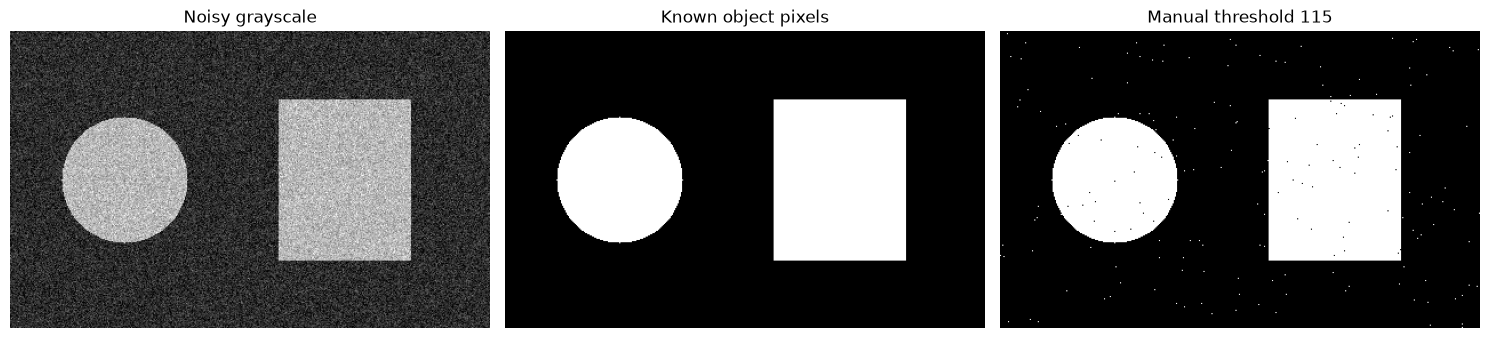

In [3]:
truth_objects = np.zeros((260, 420), dtype=np.uint8)
cv2.circle(truth_objects, (100, 130), 55, 255, -1)
cv2.rectangle(truth_objects, (235, 60), (350, 200), 255, -1)
clean_objects = np.where(truth_objects > 0, 185, 45).astype(np.uint8)
threshold_rng = np.random.default_rng(42)
noisy_objects = np.clip(clean_objects.astype(np.float32)
                        + threshold_rng.normal(0, 24, clean_objects.shape), 0, 255).astype(np.uint8)
_, manual_mask = cv2.threshold(noisy_objects, 115, 255, cv2.THRESH_BINARY)
show_images([noisy_objects, truth_objects, manual_mask], ["Noisy grayscale", "Known object pixels", "Manual threshold 115"])


## Step 2 — Let Otsu choose one threshold

Otsu searches for a threshold that separates the intensity histogram into two groups
with low within-group variation. It chooses a number, not the semantic meaning of an
object. Use `THRESH_BINARY + THRESH_OTSU`; the supplied threshold argument is ignored.
Clear two-group histograms are a good starting case; shadows, tiny targets, or overlapping
intensities make the problem harder.


Otsu on noisy input: 114.0 after Gaussian smoothing: 113.0


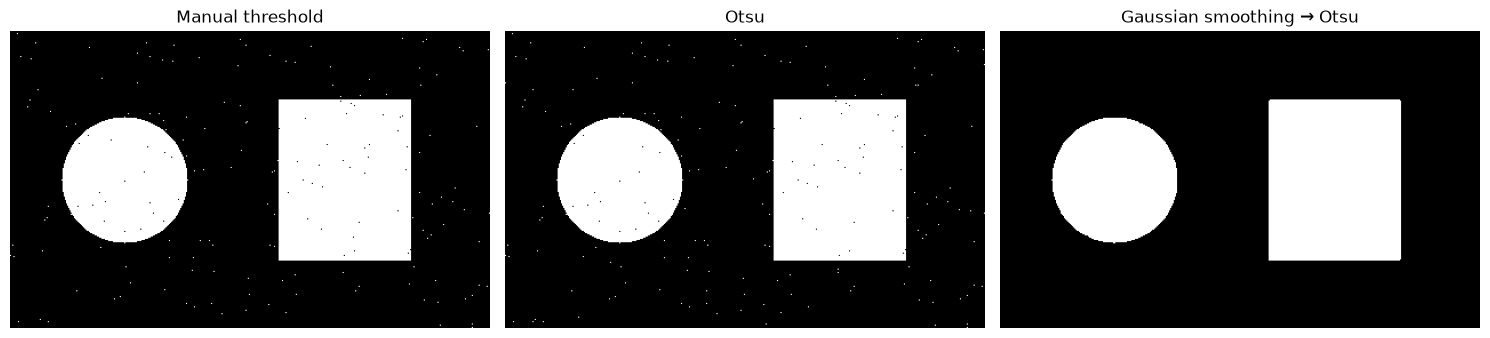

In [4]:
otsu_value, otsu_mask = cv2.threshold(noisy_objects, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
smoothed_objects = cv2.GaussianBlur(noisy_objects, (5, 5), 0)
smooth_otsu_value, smooth_otsu_mask = cv2.threshold(
    smoothed_objects, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("Otsu on noisy input:", otsu_value, "after Gaussian smoothing:", smooth_otsu_value)
show_images([manual_mask, otsu_mask, smooth_otsu_mask],
            ["Manual threshold", "Otsu", "Gaussian smoothing → Otsu"])


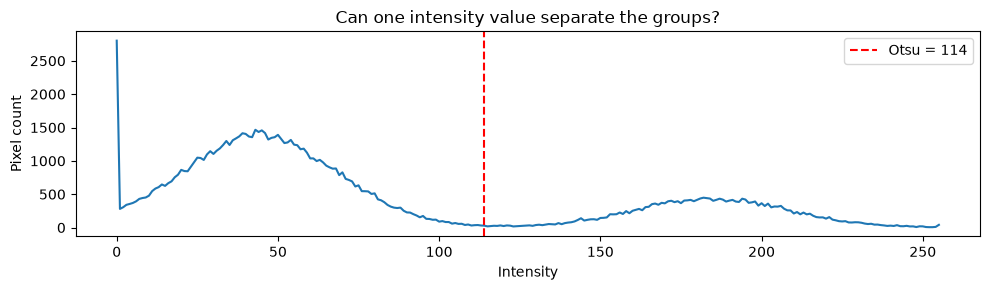

In [5]:
hist = cv2.calcHist([noisy_objects], [0], None, [256], [0, 256]).ravel()
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(hist)
ax.axvline(otsu_value, color="red", linestyle="--", label=f"Otsu = {otsu_value:.0f}")
ax.set(xlabel="Intensity", ylabel="Pixel count", title="Can one intensity value separate the groups?")
ax.legend()
plt.tight_layout()
plt.show()


Use intersection over union (IoU) to compare binary masks. A correct rejection
of background does not inflate this score: only foreground intersection and union
enter the calculation. If both masks are empty, we define their IoU as 1 for this lesson.


In [6]:
def mask_iou(predicted, truth):
    p, t = predicted > 0, truth > 0
    union = np.count_nonzero(p | t)
    return float(np.count_nonzero(p & t) / union) if union else 1.0

for name, mask in [("Manual", manual_mask), ("Otsu", otsu_mask), ("Smoothed Otsu", smooth_otsu_mask)]:
    print(f"{name:15} IoU = {mask_iou(mask, truth_objects):.4f}")
assert mask_iou(truth_objects, truth_objects) == 1.0


Manual          IoU = 0.9928
Otsu            IoU = 0.9923
Smoothed Otsu   IoU = 0.9995


## Step 3 — Handle uneven illumination with local decisions

Create a document with dark text on a background that becomes brighter from left to
right. The foreground labels come from the text drawing, before lighting or noise is
added. A global threshold may confuse shadowed paper with text or miss text in bright
regions because the intensity ranges overlap.


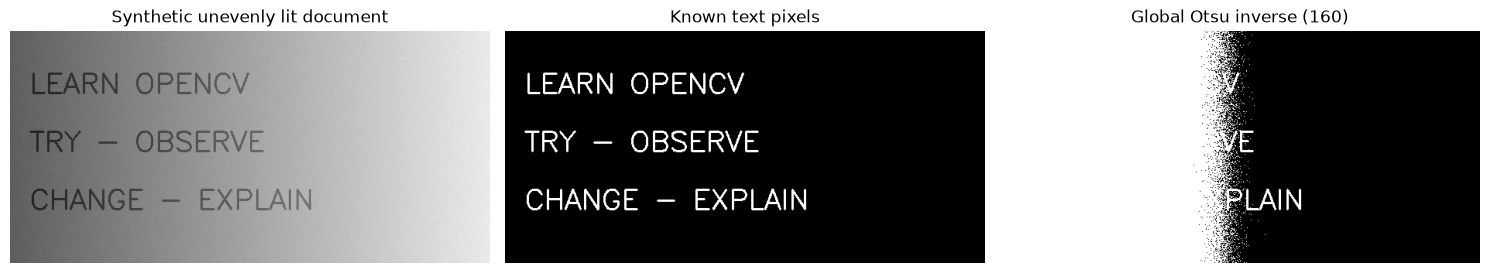

In [7]:
document_truth = np.zeros((300, 620), dtype=np.uint8)
for text, y in [("LEARN OPENCV", 80), ("TRY - OBSERVE", 155), ("CHANGE - EXPLAIN", 230)]:
    cv2.putText(document_truth, text, (25, y), cv2.FONT_HERSHEY_SIMPLEX,
                1.2, 255, 2, cv2.LINE_8)
paper = np.tile(np.linspace(95, 235, 620, dtype=np.float32), (300, 1))
document_clean = paper - (document_truth > 0).astype(np.float32) * 65
document_rng = np.random.default_rng(12)
document = np.clip(document_clean + document_rng.normal(0, 3, paper.shape), 0, 255).astype(np.uint8)
global_value, global_document = cv2.threshold(document, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
show_images([document, document_truth, global_document],
            ["Synthetic unevenly lit document", "Known text pixels", f"Global Otsu inverse ({global_value:.0f})"])


`adaptiveThreshold` estimates a local reference from a neighborhood, then subtracts
`C`. `blockSize` is the odd neighborhood width in pixels and must be greater than 1.
`ADAPTIVE_THRESH_GAUSSIAN_C` weights nearby pixels more strongly; `MEAN_C` uses a plain
average. With the inverse binary mode, sufficiently dark pixels become white foreground.
The function expects an 8-bit single-channel image.


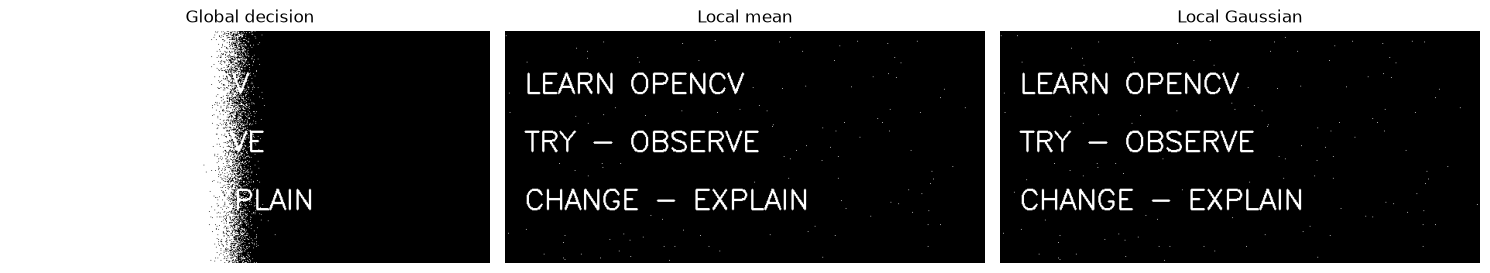

Global             IoU = 0.0757
Adaptive mean      IoU = 0.9831
Adaptive Gaussian  IoU = 0.9819


In [8]:
block_size = 31
constant_c = 10
adaptive_document = cv2.adaptiveThreshold(document, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                          cv2.THRESH_BINARY_INV, block_size, constant_c)
mean_document = cv2.adaptiveThreshold(document, 255, cv2.ADAPTIVE_THRESH_MEAN_C,
                                      cv2.THRESH_BINARY_INV, block_size, constant_c)
show_images([global_document, mean_document, adaptive_document],
            ["Global decision", "Local mean", "Local Gaussian"])
for name, mask in [("Global", global_document), ("Adaptive mean", mean_document),
                   ("Adaptive Gaussian", adaptive_document)]:
    print(f"{name:18} IoU = {mask_iou(mask, document_truth):.4f}")


### Parameter experiment

Try block sizes 11, 31, and 61, then change C from 10 to 3 or 18. Small neighborhoods
may follow the letters themselves; large neighborhoods may fail to follow illumination.
In inverse mode, increasing C generally demands a darker deviation from the local
reference, reducing selected pixels. Check both faint letters and background speckles.


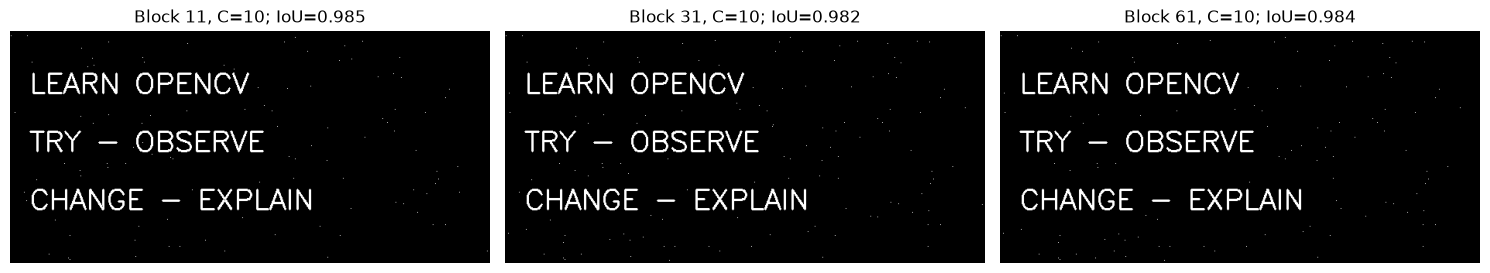

In [9]:
experiment_c = 10
block_sizes = [11, 31, 61]
adaptive_variants = [cv2.adaptiveThreshold(document, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                          cv2.THRESH_BINARY_INV, b, experiment_c) for b in block_sizes]
show_images(adaptive_variants,
            [f"Block {b}, C={experiment_c}; IoU={mask_iou(mask, document_truth):.3f}"
             for b, mask in zip(block_sizes, adaptive_variants)])


## Step 4 — Use shape rules to refine masks

Morphology operates on neighborhoods defined by a **structuring element**. For white
foreground, erosion shrinks regions and dilation expands them. `getStructuringElement`
constructs a rectangle, ellipse, or cross; its shape influences which details survive.
`iterations=1` applies one pass. More iterations can erase or merge objects.


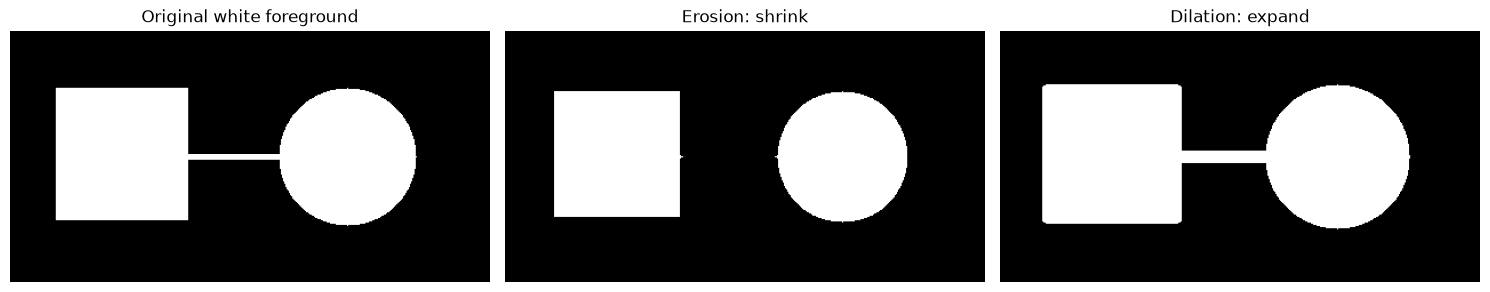

Structuring element:
 [[0 0 0 1 0 0 0]
 [0 1 1 1 1 1 0]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [0 1 1 1 1 1 0]
 [0 0 0 1 0 0 0]]


In [10]:
shape_mask = np.zeros((220, 420), dtype=np.uint8)
cv2.rectangle(shape_mask, (40, 50), (155, 165), 255, -1)
cv2.circle(shape_mask, (295, 110), 60, 255, -1)
cv2.line(shape_mask, (155, 110), (235, 110), 255, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
eroded = cv2.erode(shape_mask, kernel, iterations=1)
dilated = cv2.dilate(shape_mask, kernel, iterations=1)
show_images([shape_mask, eroded, dilated], ["Original white foreground", "Erosion: shrink", "Dilation: expand"])
assert cv2.countNonZero(eroded) <= cv2.countNonZero(shape_mask)
assert cv2.countNonZero(dilated) >= cv2.countNonZero(shape_mask)
print("Structuring element:\n", kernel)


Opening is erosion followed by dilation; it removes small foreground protrusions
and isolated speckles. Closing is dilation followed by erosion; it can fill small
background gaps and holes. These operations do not understand which structures are
important. A thin legitimate line can disappear during opening, and two nearby objects
can merge during closing.


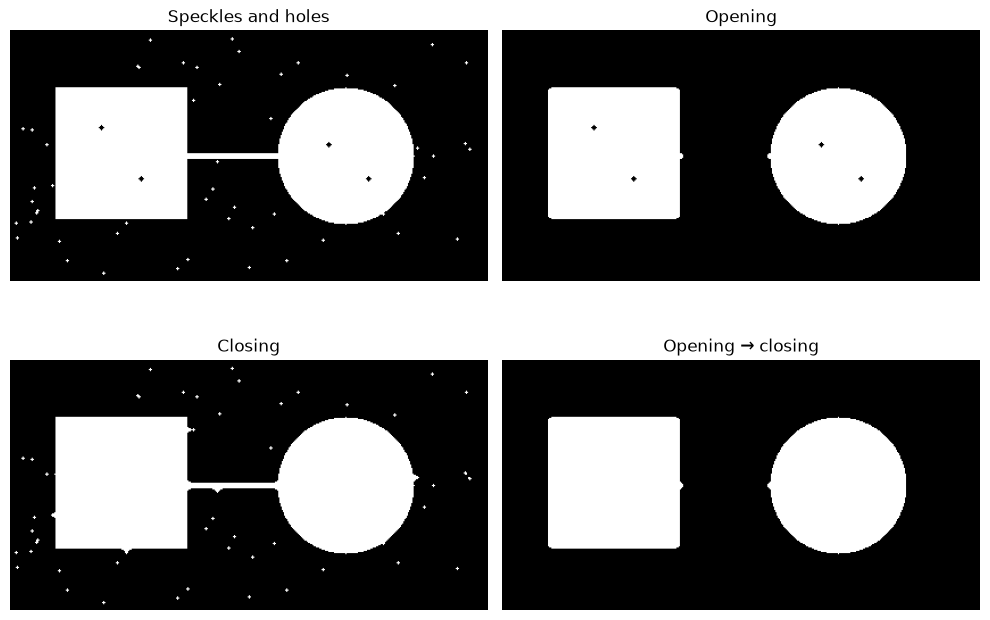

In [11]:
damaged = shape_mask.copy()
damage_rng = np.random.default_rng(23)
for x, y in damage_rng.integers([5, 5], [415, 215], size=(80, 2)):
    if damaged[y, x] == 0:
        cv2.circle(damaged, (int(x), int(y)), 1, 255, -1)
for center in [(80, 85), (115, 130), (280, 100), (315, 130)]:
    cv2.circle(damaged, center, 2, 0, -1)
opened = cv2.morphologyEx(damaged, cv2.MORPH_OPEN, kernel)
closed = cv2.morphologyEx(damaged, cv2.MORPH_CLOSE, kernel)
open_then_close = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, kernel)
show_images([damaged, opened, closed, open_then_close],
            ["Speckles and holes", "Opening", "Closing", "Opening → closing"], cols=2)


A morphological gradient is dilation minus erosion: it emphasizes the boundary
band. A top-hat is the original minus its opening, highlighting small bright structures.
A black-hat is the closing minus the original, highlighting small dark structures.
Their meaning depends on kernel size: 'small' is relative to the neighborhood.


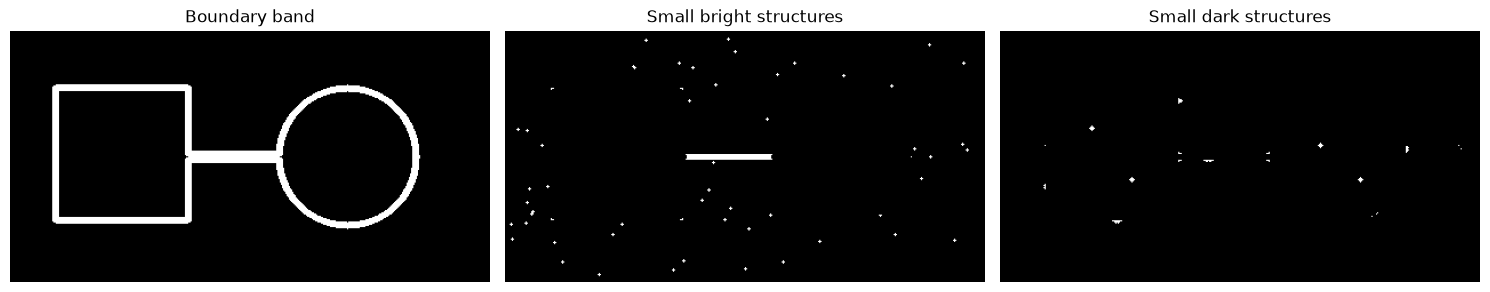

In [12]:
morph_gradient = cv2.morphologyEx(shape_mask, cv2.MORPH_GRADIENT, kernel)
top_hat = cv2.morphologyEx(damaged, cv2.MORPH_TOPHAT, kernel)
black_hat = cv2.morphologyEx(damaged, cv2.MORPH_BLACKHAT, kernel)
show_images([morph_gradient, top_hat, black_hat],
            ["Boundary band", "Small bright structures", "Small dark structures"])


## Step 5 — Evaluate cleaning without hiding lost detail

Compare the cleaned mask to the undamaged reference. A mask can look cleaner while
losing its legitimate thin connector. Larger kernels impose a stronger shape assumption.
This sweep makes that failure visible instead of treating morphology as an automatic
'cleanup' button. The best choice depends on which features the task must preserve.


Kernel 3: IoU=0.9872, area=25357
Kernel 5: IoU=0.9993, area=25143
Kernel 9: IoU=0.9835, area=24730


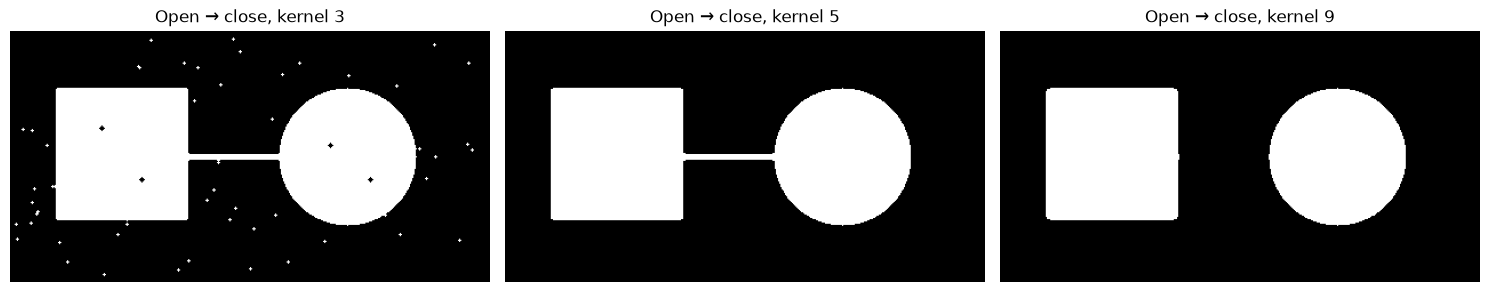

In [13]:
morph_sizes = [3, 5, 9]
cleaned_variants = []
for size in morph_sizes:
    element = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (size, size))
    result = cv2.morphologyEx(damaged, cv2.MORPH_OPEN, element)
    result = cv2.morphologyEx(result, cv2.MORPH_CLOSE, element)
    cleaned_variants.append(result)
    print(f"Kernel {size}: IoU={mask_iou(result, shape_mask):.4f}, area={cv2.countNonZero(result)}")
show_images(cleaned_variants,
            [f"Open → close, kernel {size}" for size in morph_sizes])


## Step 6 — Mini-project: recover a document's text mask

Build a pipeline of optional smoothing, adaptive thresholding, and optional morphology.
Evaluate each stage. Text is thin, so even a 3×3 opening can remove useful strokes.
Keep the simpler candidate if a refinement reduces IoU. This miniature comparison
uses one generated image for learning; a deployment decision needs separate validation
images and more varied fonts, textures, and illumination.


adaptive_raw             IoU=0.9819
adaptive_smoothed        IoU=0.9695
adaptive_then_open       IoU=0.9813
Best among these candidates: adaptive_raw


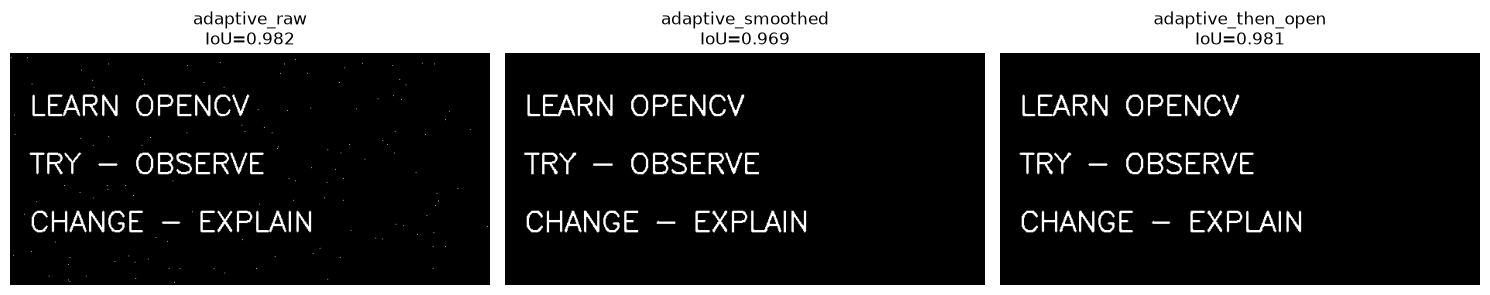

In [14]:
lightly_smoothed = cv2.GaussianBlur(document, (3, 3), 0)
smooth_adaptive = cv2.adaptiveThreshold(lightly_smoothed, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 31, 10)
small_cross = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))
opened_text = cv2.morphologyEx(smooth_adaptive, cv2.MORPH_OPEN, small_cross)
text_candidates = {
    "adaptive_raw": adaptive_document,
    "adaptive_smoothed": smooth_adaptive,
    "adaptive_then_open": opened_text,
}
scores = {name: mask_iou(mask, document_truth) for name, mask in text_candidates.items()}
best_name = max(scores, key=scores.get)
best_mask = text_candidates[best_name]
for name, score in scores.items():
    print(f"{name:24} IoU={score:.4f}")
print("Best among these candidates:", best_name)
show_images(list(text_candidates.values()),
            [f"{name}\nIoU={scores[name]:.3f}" for name in text_candidates])


An error overlay distinguishes two mistakes. **False positives** are predicted
foreground that is really background; **false negatives** are missed foreground.
Here green means correct text, red means extra pixels, and blue means missed text.
Black means correctly rejected background. This reveals where a single score hides
different kinds of failure.


False positives: 124 false negatives: 0


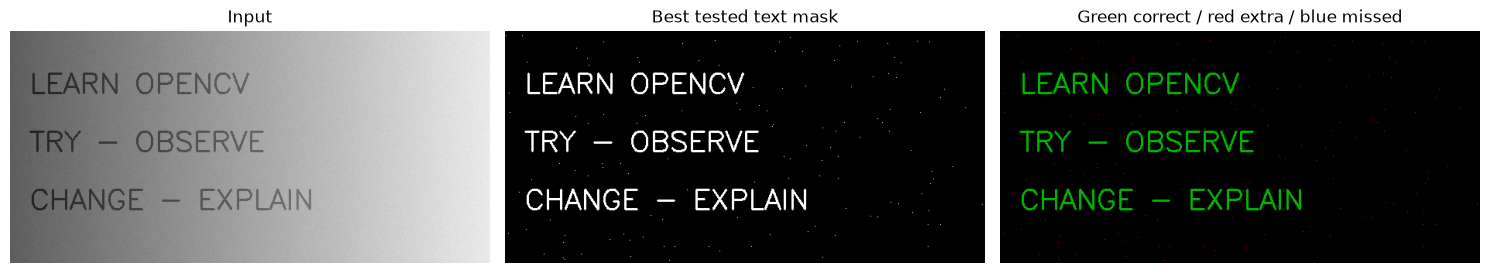

In [15]:
prediction, expected = best_mask > 0, document_truth > 0
error_overlay = np.zeros((*best_mask.shape, 3), dtype=np.uint8)
error_overlay[prediction & expected] = (0, 180, 0)
error_overlay[prediction & ~expected] = (0, 0, 255)
error_overlay[~prediction & expected] = (255, 0, 0)
false_positives = int(np.count_nonzero(prediction & ~expected))
false_negatives = int(np.count_nonzero(~prediction & expected))
print("False positives:", false_positives, "false negatives:", false_negatives)
show_images([document, best_mask, error_overlay],
            ["Input", "Best tested text mask", "Green correct / red extra / blue missed"])


In [16]:
lesson_dir = ROOT / "outputs" / "06_thresholding"
lesson_dir.mkdir(parents=True, exist_ok=True)
save_image(lesson_dir / "document_input.png", document)
save_image(lesson_dir / "document_mask.png", best_mask)
save_image(lesson_dir / "document_errors.png", error_overlay)
assert set(np.unique(best_mask)).issubset({0, 255})
print("Saved input, selected mask, and error overlay to:", lesson_dir)


Saved input, selected mask, and error overlay to: C:\Users\Hareram ray\AI\OpencvPractical\outputs\06_thresholding


### Exercises — attempt first

1. Compare global thresholds 70, 115, and 160 on `noisy_objects`. Rank by IoU.
2. Construct a white rectangle containing a tiny black hole and show how closing
   fills it. Verify the center pixel becomes white.
3. On the synthetic document, compare C values 3, 10, and 18 with block size fixed at
   31. Explain the precision/recall tradeoff by counting extra and missed pixels.


In [17]:
# Your practice area: change one parameter at a time.
# ranked_thresholds = ...


### Worked solutions

A larger C in inverse adaptive thresholding generally selects fewer pixels, which
can reduce extra detections but miss faint text. The best balance depends on the task:
missing a character and adding a background speck may have different costs.


Global thresholds ranked by IoU: [(0.9927603203943315, 115), (0.8432624937095963, 160), (0.689339559706471, 70)]


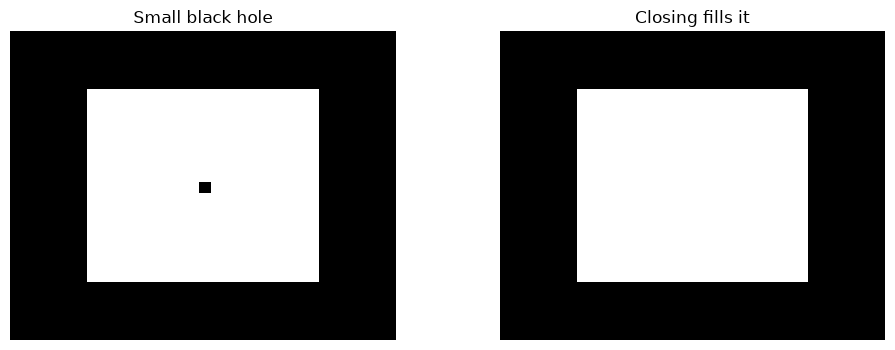

C= 3: extra=29963, missed=    0, IoU=0.1835
C=10: extra=  124, missed=    0, IoU=0.9819
C=18: extra=    0, missed=    0, IoU=1.0000


In [18]:
ranked_thresholds = []
for threshold in [70, 115, 160]:
    _, mask = cv2.threshold(noisy_objects, threshold, 255, cv2.THRESH_BINARY)
    ranked_thresholds.append((mask_iou(mask, truth_objects), threshold))
print("Global thresholds ranked by IoU:", sorted(ranked_thresholds, reverse=True))

hole_example = np.zeros((80, 100), dtype=np.uint8)
hole_example[15:65, 20:80] = 255
hole_example[39:42, 49:52] = 0
hole_filled = cv2.morphologyEx(hole_example, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
assert hole_filled[40, 50] == 255
show_images([hole_example, hole_filled], ["Small black hole", "Closing fills it"], cols=2)

for c_value in [3, 10, 18]:
    candidate = cv2.adaptiveThreshold(document, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                      cv2.THRESH_BINARY_INV, 31, c_value) > 0
    expected = document_truth > 0
    extra = np.count_nonzero(candidate & ~expected)
    missed = np.count_nonzero(~candidate & expected)
    print(f"C={c_value:2}: extra={extra:5}, missed={missed:5}, IoU={mask_iou(candidate, expected):.4f}")


### Reflection and next step

- Why does Otsu's returned threshold differ between the noisy and smoothed inputs?
- Why is an inverse threshold convenient for dark ink on bright paper?
- Which legitimate structure did a large opening remove in the shape experiment?
- Why should you inspect false positives and false negatives separately?
- Can you explain the full pipeline: image → grayscale → threshold → optional shape
  refinement → evaluation → saved artifact?

You now have the foundations for contours, object measurements, geometric transforms,
and feature-based methods. Rebuild one mini-project using your own local image before
moving on, and record which assumptions stop working.

Official references: [Thresholding](https://docs.opencv.org/4.x/d7/d4d/tutorial_py_thresholding.html),
[Morphological transformations](https://docs.opencv.org/4.x/d9/d61/tutorial_py_morphological_ops.html).
